# Respecting time order in walk-forward validation

An expanding walk-forward fold tests a later block and trains only on observations ending before a declared gap:

$$
S_k=\{a_k,\ldots,b_k\},
\qquad
T_k^{\mathrm{expand}}=\{1,\ldots,a_k-g-1\}.
$$

Here, $S_k$ is test fold $k$; $a_k$ and $b_k$ are its first and last positions; $g$ is the gap length. $T_k^{\mathrm{expand}}$ is the expanding training set; positions are written from one for clarity; $k$ indexes folds.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.backtest.validation import KFold, PurgedKFold, WalkForward

FIGURES = ROOT / "outputs" / "figures" / "16_temporal_cross_validation"
TABLES = ROOT / "outputs" / "tables" / "16_temporal_cross_validation"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

minute_data = raw.set_index("time")
bars = pd.DataFrame({
    "Close": minute_data["close"].resample("15min").last(),
    "Volume": minute_data["volume"].resample("15min").sum(),
    "Quote volume": minute_data["quote_volume"].resample("15min").sum(),
    "Trades": minute_data["trades"].resample("15min").sum(),
}).dropna()
log_close = np.log(bars["Close"])
one_bar_return = log_close.diff()
feature_frame = pd.DataFrame({
    "Previous return": one_bar_return.shift(1),
    "One-hour return": log_close.diff(4).shift(1),
    "Past volatility": one_bar_return.shift(1).rolling(16).std(),
    "Log volume change": np.log1p(bars["Volume"]).diff().shift(1),
    "Log quote-volume change": np.log1p(bars["Quote volume"]).diff().shift(1),
    "Log trade-count change": np.log1p(bars["Trades"]).diff().shift(1),
})
label_horizon = 8
forward_return = (log_close.shift(-label_horizon) - log_close).rename("Forward return")
direction = forward_return.gt(0).where(forward_return.notna()).astype("Int64").rename("Direction")
end_time = bars.index.to_series().shift(-label_horizon).rename("End time")
public_frame = pd.concat([feature_frame, direction, forward_return, end_time], axis=1).dropna()
public_x = public_frame[feature_frame.columns].astype(float)
public_y = public_frame["Direction"].astype(int)
event_times = public_frame["End time"]

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def overlap_count(train_indices, test_indices, times):
    allowed = PurgedKFold.filtered_training_indices_with_embargo(times, times.iloc[test_indices], embargo_fraction=0, continous_test_times=False)
    allowed_positions = set(times.index.get_indexer(allowed.index).tolist())
    return sum(int(int(index) not in allowed_positions) for index in train_indices)

def score_splits(name, splits):
    predictions = np.full(len(public_x), np.nan)
    records = []
    for fold, (train_indices, test_indices) in enumerate(splits, start=1):
        if len(train_indices) == 0 or public_y.iloc[train_indices].nunique() < 2:
            records.append({"Method": name, "Fold": fold, "Training observations": len(train_indices), "Test observations": len(test_indices), "Accuracy": np.nan})
            continue
        estimator = LogisticRegression(max_iter=1000, solver="lbfgs")
        estimator.fit(public_x.iloc[train_indices], public_y.iloc[train_indices])
        fold_predictions = estimator.predict(public_x.iloc[test_indices])
        predictions[test_indices] = fold_predictions
        records.append({"Method": name, "Fold": fold, "Training observations": len(train_indices), "Test observations": len(test_indices), "Accuracy": accuracy_score(public_y.iloc[test_indices], fold_predictions)})
    return pd.DataFrame(records), predictions

def split_matrix(split_sets, length):
    matrix = np.zeros((len(split_sets), length), dtype=int)
    for row, (train_indices, test_indices) in enumerate(split_sets):
        matrix[row, train_indices] = 1
        matrix[row, test_indices] = 2
    return matrix

split_colors = ListedColormap([palette["muted"], palette["cyan"], palette["rose"], palette["amber"], palette["violet"]])
split_norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), split_colors.N)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Comparing expanding windows with rolling windows

,Method,Fold,Training observations,Test observations,Training begins,Training ends,Test begins,Test ends
0,"Expanding, no gap",1,0,492,Not available,Not available,2021-01-01 04:15:00,2021-01-06 07:00:00
1,"Expanding, no gap",2,492,492,2021-01-01 04:15:00,2021-01-06 07:00:00,2021-01-06 07:15:00,2021-01-11 10:00:00
2,"Expanding, no gap",3,984,492,2021-01-01 04:15:00,2021-01-11 10:00:00,2021-01-11 10:15:00,2021-01-16 13:00:00
3,"Expanding, no gap",4,1476,492,2021-01-01 04:15:00,2021-01-16 13:00:00,2021-01-16 13:15:00,2021-01-21 16:00:00
4,"Expanding, no gap",5,1968,492,2021-01-01 04:15:00,2021-01-21 16:00:00,2021-01-21 16:15:00,2021-01-26 19:00:00
5,"Expanding, no gap",6,2460,491,2021-01-01 04:15:00,2021-01-26 19:00:00,2021-01-26 19:15:00,2021-01-31 21:45:00
6,"Expanding, eight-bar gap",1,0,492,Not available,Not available,2021-01-01 04:15:00,2021-01-06 07:00:00
7,"Expanding, eight-bar gap",2,484,492,2021-01-01 04:15:00,2021-01-06 05:00:00,2021-01-06 07:15:00,2021-01-11 10:00:00
8,"Expanding, eight-bar gap",3,976,492,2021-01-01 04:15:00,2021-01-11 08:00:00,2021-01-11 10:15:00,2021-01-16 13:00:00
9,"Expanding, eight-bar gap",4,1468,492,2021-01-01 04:15:00,2021-01-16 11:00:00,2021-01-16 13:15:00,2021-01-21 16:00:00


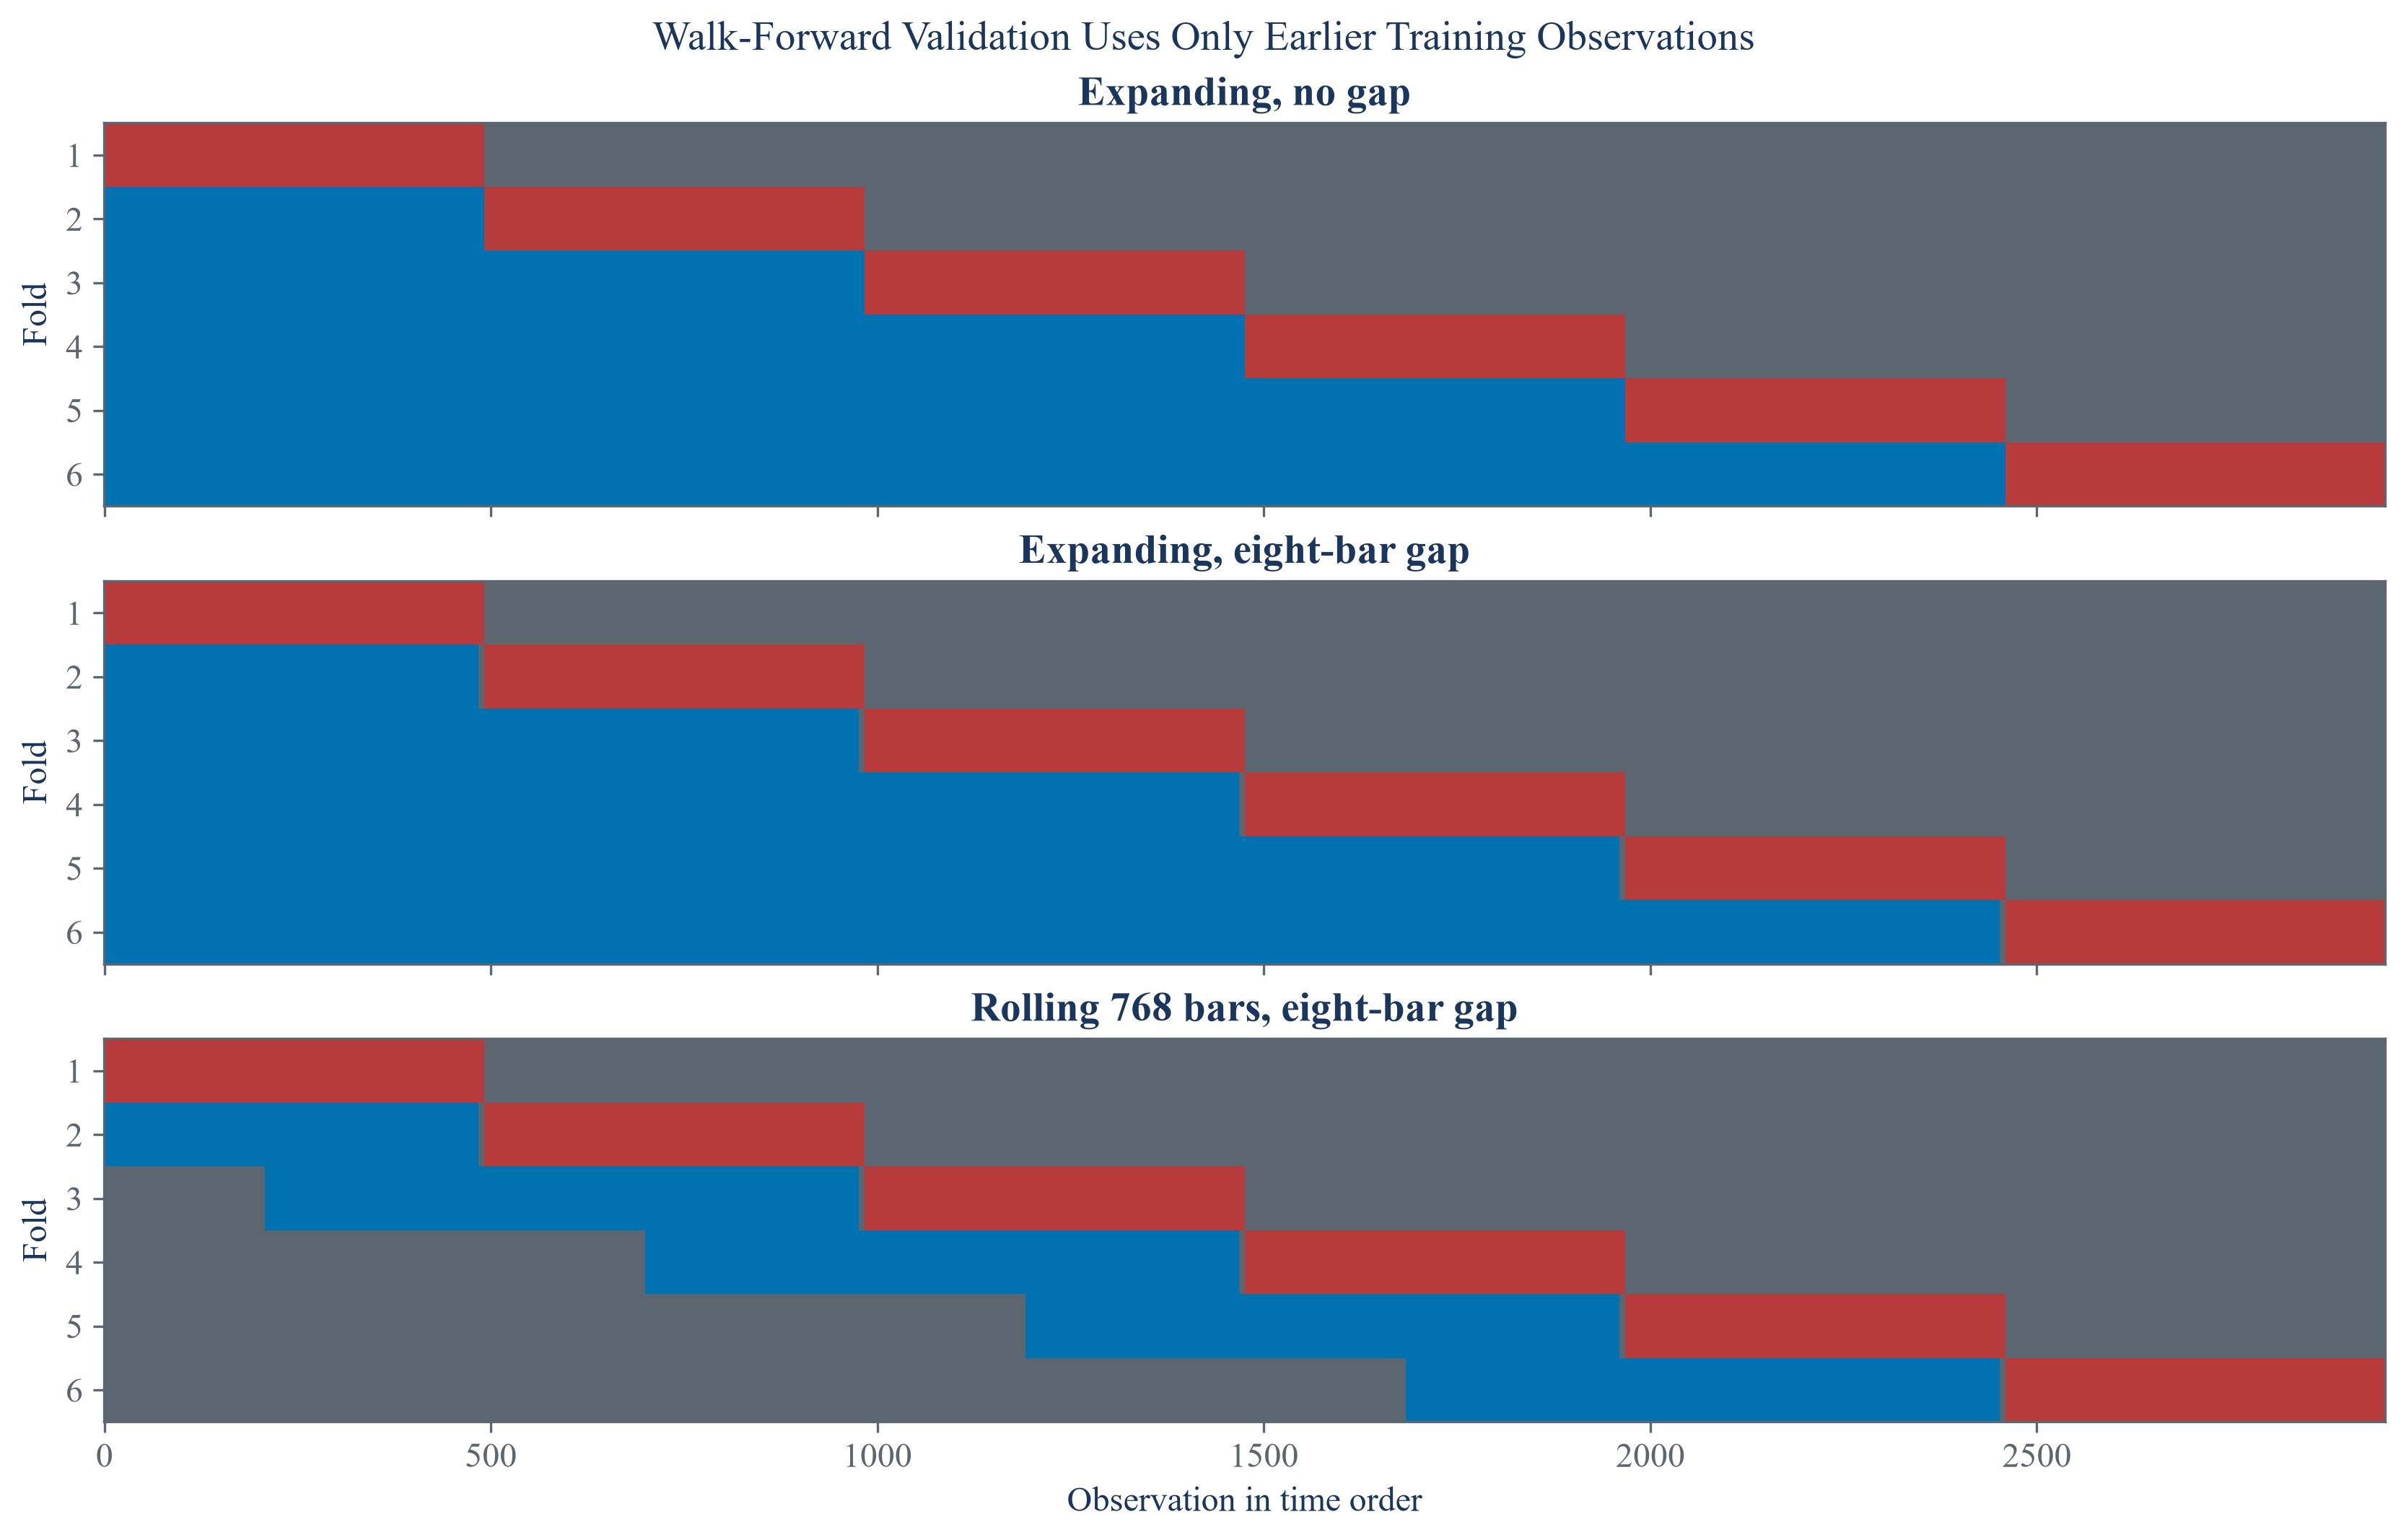

In [2]:
n_splits = 6
walk_rules = [
    ("Expanding, no gap", WalkForward(n_splits=n_splits, gap=0)),
    ("Expanding, eight-bar gap", WalkForward(n_splits=n_splits, gap=8)),
    ("Rolling 768 bars, eight-bar gap", WalkForward(n_splits=n_splits, max_train_size=768, gap=8)),
]
walk_splits = {name: list(rule.split(public_x, public_y)) for name, rule in walk_rules}
walk_records = []
for name, splits in walk_splits.items():
    for fold, (train_indices, test_indices) in enumerate(splits, start=1):
        walk_records.append({
            "Method": name,
            "Fold": fold,
            "Training observations": len(train_indices),
            "Test observations": len(test_indices),
            "Training begins": str(public_x.index[train_indices[0]]) if len(train_indices) else "Not available",
            "Training ends": str(public_x.index[train_indices[-1]]) if len(train_indices) else "Not available",
            "Test begins": str(public_x.index[test_indices[0]]),
            "Test ends": str(public_x.index[test_indices[-1]]),
        })
walk_forward_windows = pd.DataFrame(walk_records)
save_table(walk_forward_windows, "walk_forward_windows", "Expanding and rolling walk-forward windows on the public data.", "tab:chapter14-walk-forward-windows", fit=True)
display(walk_forward_windows)

figure, axes = plt.subplots(3, 1, figsize=(11.0, 7.0), sharex=True, constrained_layout=True)
for axis, (name, _) in zip(axes, walk_rules):
    matrix = split_matrix(walk_splits[name], len(public_x))
    axis.imshow(matrix, aspect="auto", interpolation="nearest", cmap=split_colors, norm=split_norm)
    axis.set_title(name)
    axis.set_ylabel("Fold")
    axis.set_yticks(np.arange(n_splits))
    axis.set_yticklabels(np.arange(1, n_splits + 1))
axes[-1].set_xlabel("Observation in time order")
figure.suptitle("Walk-Forward Validation Uses Only Earlier Training Observations")
figure.savefig(FIGURES / "walk_forward_geometry.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "walk_forward_geometry.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "walk_forward_geometry.png")))
plt.close(figure)

A rolling walk-forward fold keeps at most the most recent $M$ eligible observations before the gap:

$$
T_k^{\mathrm{roll}}
=\{\max(1,a_k-g-M),\ldots,a_k-g-1\}.
$$

Here, $T_k^{\mathrm{roll}}$ is the rolling training set; $a_k$ is the first test position; $g$ is the gap. $M$ is the maximum training size; $k$ indexes folds; $\max$ prevents the lower endpoint from preceding the sample.

## Time-Order Audit

In [3]:
comparison_splits = {
    "Random folds": list(KFold(n_splits=n_splits, shuffle=True, random_seed=14).split(public_x, public_y)),
    "Ordered folds": list(KFold(n_splits=n_splits, shuffle=False).split(public_x, public_y)),
    "Purged folds": list(PurgedKFold(n_splits=n_splits, times=event_times, embargo=0.01).split(public_x, public_y)),
    "Walk-forward with eight-bar gap": walk_splits["Expanding, eight-bar gap"],
}
order_records = []
for method, splits in comparison_splits.items():
    for fold, (train_indices, test_indices) in enumerate(splits, start=1):
        first_test = test_indices.min()
        earlier_train = train_indices[train_indices < first_test]
        crossing = int(np.sum(event_times.iloc[earlier_train].to_numpy() >= public_x.index[first_test]))
        order_records.append({
            "Method": method,
            "Fold": fold,
            "Training rows on or after first test row": int(np.sum(train_indices >= first_test)),
            "Earlier training labels reaching test start": crossing,
        })
time_order_by_fold = pd.DataFrame(order_records)
time_order_audit = time_order_by_fold.groupby("Method", sort=False).agg({
    "Training rows on or after first test row": ["mean", "max"],
    "Earlier training labels reaching test start": ["mean", "max"],
}).reset_index()
time_order_audit.columns = ["Method", "Mean non-earlier training rows", "Maximum non-earlier training rows", "Mean labels crossing test start", "Maximum labels crossing test start"]
save_table(time_order_audit, "time_order_audit", "Time-order and label-end checks across validation rules.", "tab:chapter14-time-order-audit", fit=True)
display(time_order_audit.round(6))

,Method,Mean non-earlier training rows,Maximum non-earlier training rows,Mean labels crossing test start,Maximum labels crossing test start
0,Random folds,2455.166667,2459,3.166667,8
1,Ordered folds,1229.166667,2459,6.666667,8
2,Purged folds,1198.333333,2422,0,0
3,Walk-forward with eight-bar gap,0,0,0,0


Walk-forward error is the test-size-weighted average of losses from folds that have a usable training history:

$$
\widehat R_{\mathrm{WF}}
=\frac{\sum_{k\in\mathcal K_+}|S_k|R_k}
{\sum_{k\in\mathcal K_+}|S_k|},
\qquad
R_k=\frac1{|S_k|}\sum_{i\in S_k}
\one\!\left\{\widehat y_i\neq y_i\right\}.
$$

Here, $\mathcal K_+$ is the set of folds with training data; $S_k$ is test fold $k$; $|S_k|$ is its size. $R_k$ is fold error; $y_i$ and $\widehat y_i$ are observed and predicted labels; $\widehat R_{\mathrm{WF}}$ is combined error.

## Public Walk-Forward Results

,Method,Scored folds,Mean accuracy,Accuracy spread,Minimum accuracy,Maximum accuracy
0,"Expanding, no gap",5,0.500205,0.022638,0.461382,0.520325
1,"Expanding, eight-bar gap",5,0.501019,0.022996,0.461382,0.520325
2,"Rolling 768 bars, eight-bar gap",5,0.508742,0.013588,0.491870,0.528455


,Training window,Gap in bars,Scored observations,Mean training observations,Accuracy
0,Expanding,0,2459,1476,0.500203
1,Expanding,4,2459,1472,0.500610
2,Expanding,8,2459,1468,0.501017
3,Expanding,16,2459,1460,0.501423
4,Rolling 384 bars,0,2459,384,0.493697
5,Rolling 384 bars,4,2459,384,0.491663
6,Rolling 384 bars,8,2459,384,0.494510
7,Rolling 384 bars,16,2459,384,0.487597
8,Rolling 768 bars,0,2459,712.8,0.507930
9,Rolling 768 bars,4,2459,712,0.507117


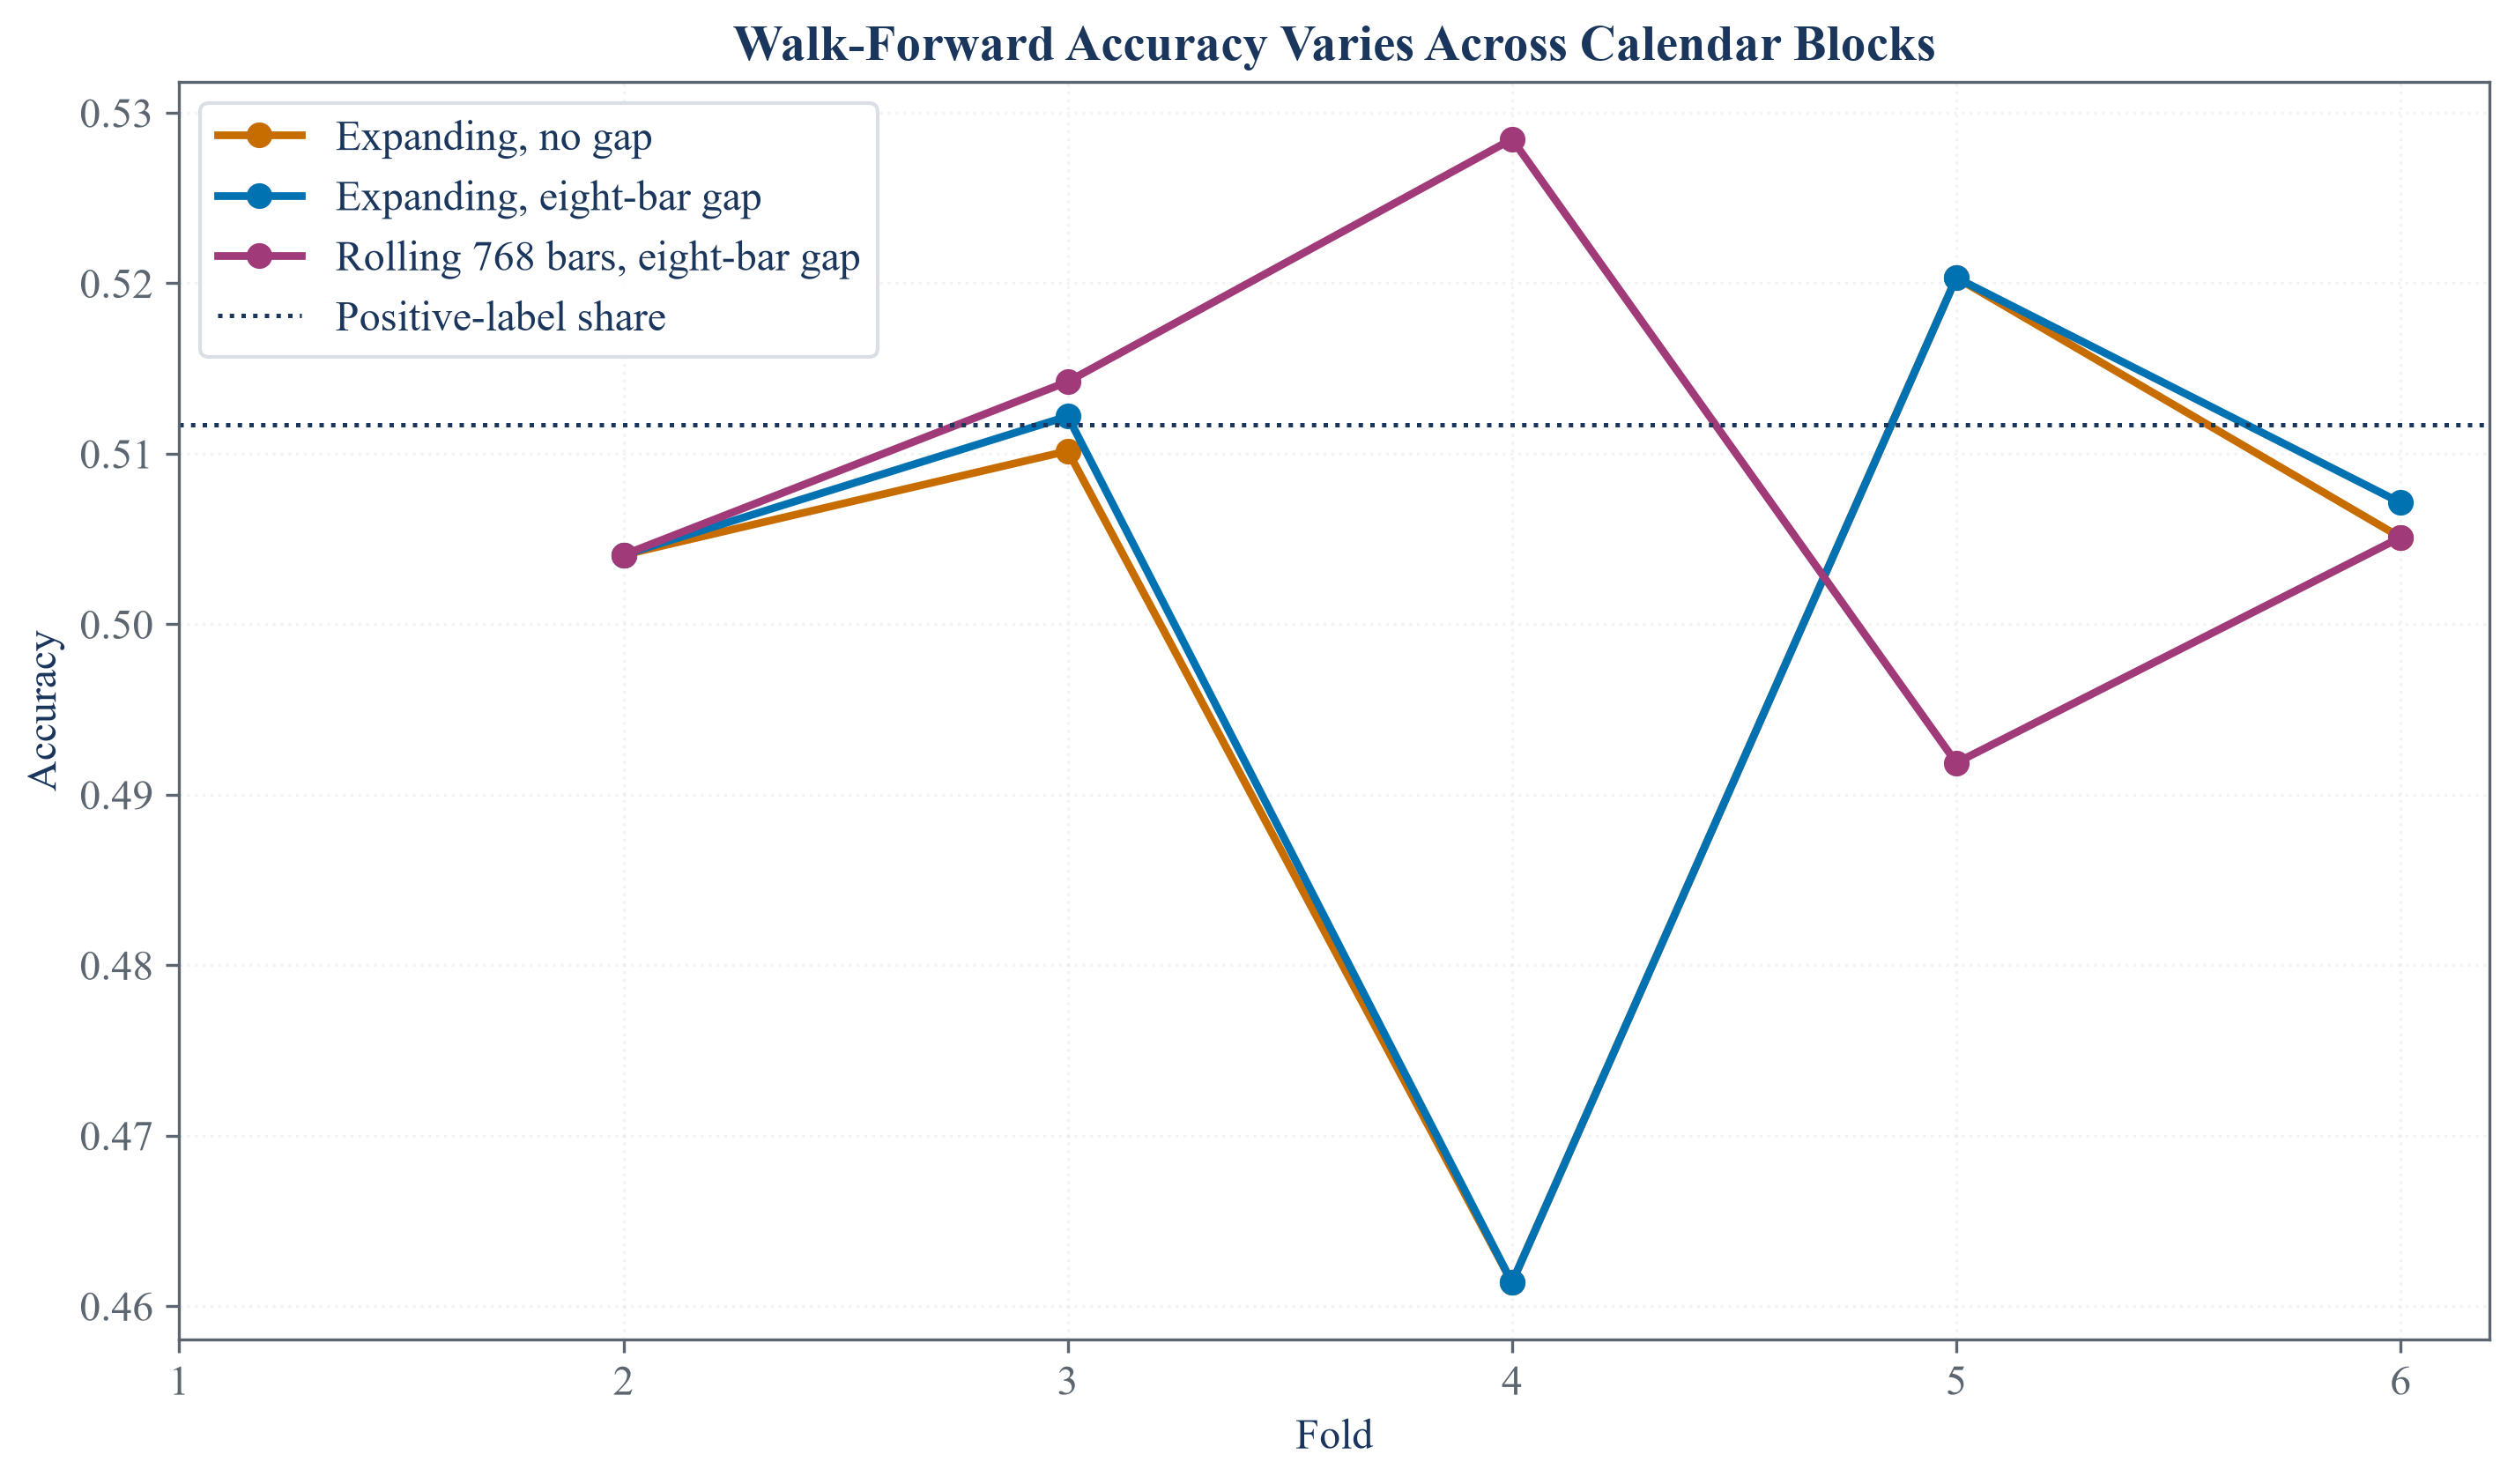

In [4]:
walk_score_frames = []
walk_predictions = {}
for name, _ in walk_rules:
    scores, predictions = score_splits(name, walk_splits[name])
    walk_score_frames.append(scores)
    walk_predictions[name] = predictions
walk_fold_scores = pd.concat(walk_score_frames, ignore_index=True)
walk_score_summary = walk_fold_scores.groupby("Method", sort=False)["Accuracy"].agg(["count", "mean", "std", "min", "max"]).reset_index()
walk_score_summary.columns = ["Method", "Scored folds", "Mean accuracy", "Accuracy spread", "Minimum accuracy", "Maximum accuracy"]
save_table(walk_score_summary, "walk_forward_accuracy", "Public walk-forward accuracy for expanding and rolling training windows.", "tab:chapter14-walk-forward-accuracy", fit=True)
display(walk_score_summary.round(6))

gap_records = []
for maximum in [None, 384, 768]:
    for gap in [0, 4, 8, 16]:
        name = "Expanding" if maximum is None else f"Rolling {maximum} bars"
        splits = list(WalkForward(n_splits=n_splits, max_train_size=maximum, gap=gap).split(public_x, public_y))
        scores, predictions = score_splits(name, splits)
        valid = np.isfinite(predictions)
        gap_records.append({
            "Training window": name,
            "Gap in bars": gap,
            "Scored observations": int(valid.sum()),
            "Mean training observations": float(scores.loc[scores["Training observations"] > 0, "Training observations"].mean()),
            "Accuracy": accuracy_score(public_y.iloc[np.flatnonzero(valid)], predictions[valid]),
        })
gap_window_sensitivity = pd.DataFrame(gap_records)
save_table(gap_window_sensitivity, "gap_window_sensitivity", "Sensitivity of public walk-forward accuracy to the gap and training-window length.", "tab:chapter14-gap-window-sensitivity", fit=True)
display(gap_window_sensitivity.round(6))

figure, axis = plt.subplots(figsize=(9.4, 5.5), constrained_layout=True)
colors = [palette["amber"], palette["cyan"], palette["violet"]]
for color, (name, _) in zip(colors, walk_rules):
    current = walk_fold_scores[walk_fold_scores["Method"] == name]
    axis.plot(current["Fold"], current["Accuracy"], marker="o", linewidth=2.1, color=color, label=name)
axis.axhline(public_y.mean(), color=palette["text"], linestyle=":", linewidth=1.2, label="Positive-label share")
axis.set_title("Walk-Forward Accuracy Varies Across Calendar Blocks")
axis.set_xlabel("Fold")
axis.set_ylabel("Accuracy")
axis.set_xticks(np.arange(1, n_splits + 1))
axis.grid(alpha=0.35)
axis.legend()
figure.savefig(FIGURES / "walk_forward_accuracy.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "walk_forward_accuracy.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "walk_forward_accuracy.png")))
plt.close(figure)

## Tests

In [5]:
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert walk_forward_windows.shape == (18, 8)
assert (walk_forward_windows.loc[walk_forward_windows["Fold"] == 1, "Training observations"] == 0).all()
assert (walk_forward_windows.loc[walk_forward_windows["Fold"] > 1, "Training observations"] > 0).all()
assert time_order_by_fold.shape == (24, 4)
walk_audit = time_order_audit[time_order_audit["Method"] == "Walk-forward with eight-bar gap"].iloc[0]
assert walk_audit["Maximum non-earlier training rows"] == 0
assert walk_audit["Maximum labels crossing test start"] == 0
assert time_order_audit.loc[time_order_audit["Method"] == "Purged folds", "Maximum labels crossing test start"].iloc[0] == 0
assert time_order_audit.loc[time_order_audit["Method"] == "Purged folds", "Maximum non-earlier training rows"].iloc[0] > 0
assert walk_fold_scores.shape == (18, 5)
assert walk_fold_scores["Accuracy"].dropna().between(0, 1).all()
assert walk_score_summary["Scored folds"].eq(5).all()
assert gap_window_sensitivity.shape == (12, 5)
assert gap_window_sensitivity["Accuracy"].between(0, 1).all()
assert np.isnan(walk_predictions["Expanding, eight-bar gap"][:len(walk_splits["Expanding, eight-bar gap"][0][1])]).all()
assert (FIGURES / "walk_forward_geometry.pdf").is_file()
assert (FIGURES / "walk_forward_accuracy.pdf").is_file()
assert (TABLES / "walk_forward_windows.tex").is_file()
assert (TABLES / "time_order_audit.tex").is_file()
assert (TABLES / "walk_forward_accuracy.tex").is_file()
assert (TABLES / "gap_window_sensitivity.tex").is_file()